# GIAI ĐOẠN 4: HUẤN LUYỆN, ĐÁNH GIÁ MÔ HÌNH HỌC MÁY



![Quy trình tổng thể](../figures/00_quy_trinh_tong_the.png)

### 1. Khai báo Thư viện & Thiết lập Cấu hình Môi trường


In [2]:
import os
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
import xgboost as xgb

# Cấu hình thẩm mỹ đồ họa chuẩn xuất bản
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['figure.dpi'] = 120

RANDOM_STATE = 42
os.makedirs('../models', exist_ok=True)
os.makedirs('../figures', exist_ok=True)
print("Môi trường Machine Learning đã sẵn sàng!")

Môi trường Machine Learning đã sẵn sàng!


### 2. Nạp Dữ liệu Sạch & Phân Tách Đặc Trưng ($X$) - Biến Mục Tiêu ($y$)
- Đọc tập dữ liệu đã hoàn thiện tiền xử lý và bóc tách đặc trưng từ [`datas/laptop_price_cleaned.csv`](../datas/laptop_price_cleaned.csv) (1.273 dòng, 21 cột).
- **Chiến lược biến mục tiêu:** 
  - Huấn luyện trên biến `log_price = np.log1p(Price)` nhằm ổn định phương sai sai số, đưa phân phối lệch phải ($Skew=1.51$) về dạng chuẩn đối xứng ($Skew=-0.18$).
  - Giữ lại biến gốc `Price (Euro)` để đối soát sai số ngoài mẫu trên quy mô tiền tệ thực tế thông qua hàm nghịch đảo `np.expm1(y_pred)`.


In [3]:
data_path = '../datas/laptop_price_cleaned.csv'
df = pd.read_csv(data_path)

print(f"Kích thước tập dữ liệu sạch: {df.shape[0]:,} dòng, {df.shape[1]} cột.")
print(f"Số lượng giá trị khuyết thiếu (Missing Values): {df.isnull().sum().sum()}")

num_features = [
    'Inches', 'CPU_Frequency (GHz)', 'RAM (GB)', 'Weight (kg)', 
    'Touchscreen', 'IPS_Panel', 'PPI', 
    'SSD_GB', 'HDD_GB', 'Flash_Storage_GB', 'Hybrid_GB', 'Total_Storage_GB', 
    'Has_SSD', 'GPU_Dedicated'
]

cat_features = [
    'Company', 'TypeName', 'CPU_Tier', 'GPU_Brand_Cat', 'OpSys_Group'
]

feature_cols = num_features + cat_features
X = df[feature_cols].copy()
y = df['log_price'].copy()
y_raw = df['Price (Euro)'].copy()

print(f"Tổng số đặc trưng đầu vào X: {len(feature_cols)} (Gồm {len(num_features)} biến số và {len(cat_features)} biến danh mục).")
display(X.head())

Kích thước tập dữ liệu sạch: 1,273 dòng, 21 cột.
Số lượng giá trị khuyết thiếu (Missing Values): 0
Tổng số đặc trưng đầu vào X: 19 (Gồm 14 biến số và 5 biến danh mục).


,Inches,CPU_Frequency (GHz),RAM (GB),Weight (kg),Touchscreen,IPS_Panel,PPI,SSD_GB,HDD_GB,Flash_Storage_GB,Hybrid_GB,Total_Storage_GB,Has_SSD,GPU_Dedicated,Company,TypeName,CPU_Tier,GPU_Brand_Cat,OpSys_Group
0,13.3,2.3,8,1.37,0,1,226.98,128.0,0.0,0.0,0.0,128.0,1,0,Apple,Ultrabook,Intel Core i5,Intel (Integrated),macOS
1,13.3,1.8,8,1.34,0,0,127.68,0.0,0.0,128.0,0.0,128.0,0,0,Apple,Ultrabook,Intel Core i5,Intel (Integrated),macOS
2,15.6,2.5,8,1.86,0,0,141.21,256.0,0.0,0.0,0.0,256.0,1,0,HP,Notebook,Intel Core i5,Intel (Integrated),No OS
3,15.4,2.7,16,1.83,0,1,220.53,512.0,0.0,0.0,0.0,512.0,1,1,Apple,Ultrabook,Intel Core i7,AMD (Dedicated),macOS
4,13.3,3.1,8,1.37,0,1,226.98,256.0,0.0,0.0,0.0,256.0,1,0,Apple,Ultrabook,Intel Core i5,Intel (Integrated),macOS


### 3. Phân Chia Tập Huấn Luyện & Kiểm Thử (Train/Test Split)
- Tỷ lệ phân chia kinh điển **80% Train (1.018 máy) / 20% Test (255 máy)**.
- Cố định `random_state=42` bảo đảm tính khách quan và tính tái lập.


In [4]:
X_train, X_test, y_train, y_test, y_train_raw, y_test_raw = train_test_split(
    X, y, y_raw, test_size=0.2, random_state=RANDOM_STATE
)

print("=" * 60)
print("KẾT QUẢ PHÂN CHIA DỮ LIỆU:")
print(f"  Tập huấn luyện (Train set): {X_train.shape[0]:,} mẫu ({X_train.shape[0]/len(df)*100:.1f}%)")
print(f"  Tập kiểm thử   (Test set) : {X_test.shape[0]:,} mẫu ({X_test.shape[0]/len(df)*100:.1f}%)")
print(f"  Số lượng đặc trưng        : {X_train.shape[1]} cột")
print("=" * 60)

KẾT QUẢ PHÂN CHIA DỮ LIỆU:
  Tập huấn luyện (Train set): 1,018 mẫu (80.0%)
  Tập kiểm thử   (Test set) : 255 mẫu (20.0%)
  Số lượng đặc trưng        : 19 cột


### 4. Thiết Kế Pipeline 
- Sử dụng `ColumnTransformer` của Scikit-Learn:
  1. **Nhánh mô hình Tuyến tính (`preprocessor_linear`):**
     - Biến định lượng: Chuẩn hóa Z-score với `StandardScaler()`.
     - Biến danh mục: Mã hóa `OneHotEncoder(drop='first', handle_unknown='ignore')` nhằm triệt tiêu hiện tượng Đa cộng tuyến hoàn hảo (Dummy Variable Trap).
  2. **Nhánh mô hình Dạng cây (`preprocessor_tree`):**
     - Biến định lượng: Giữ nguyên thang đo tự nhiên (`passthrough`) vì các thuật toán cây bất biến với các phép biến đổi đơn điệu.
     - Biến danh mục: Mã hóa `OneHotEncoder(handle_unknown='ignore')` không cần drop cột gốc.

In [5]:
def build_preprocessors(num_cols, cat_cols):
    prep_linear = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), num_cols),
            ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
        ]
    )
    
    prep_tree = ColumnTransformer(
        transformers=[
            ('num', 'passthrough', num_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
        ]
    )
    
    return prep_linear, prep_tree

prep_linear, prep_tree = build_preprocessors(num_features, cat_features)
print("Xây dựng thành công 2 bộ tiền xử lý Pipeline chuyên biệt!")

Xây dựng thành công 2 bộ tiền xử lý Pipeline chuyên biệt!


---
# PHẦN II: TIẾN TRÌNH 4 CẤP ĐỘ MÔ HÌNH HỒI QUY 

### Cấp độ 1: Hồi quy Tuyến tính Đơn biến (Simple Linear Regression - SLR)
- **Cơ sở lý thuyết:** Thiết lập mối quan hệ tuyến tính giữa một biến giải thích duy nhất $X$ và biến mục tiêu $y$:
  $$\hat{y} = \beta_0 + \beta_1 X$$
  Trong đó: $\beta_1 = \frac{\sum (X_i - \bar{X})(y_i - \bar{y})}{\sum (X_i - \bar{X})^2}$ (hệ số góc), $\beta_0 = \bar{y} - \beta_1 \bar{X}$ (hệ số chặn).
- **Lựa chọn biến số:** Dựa trên ma trận tương quan Pearson ở Step 2, hai đặc trưng có tương quan tuyến tính mạnh nhất với giá bán là **`RAM (GB)`** ($r \approx 0.74$) và **`PPI`** ($r \approx 0.48$).

In [6]:
slr_ram = LinearRegression()
slr_ram.fit(X_train[['RAM (GB)']], y_train)

y_pred_slr_ram_tr = slr_ram.predict(X_train[['RAM (GB)']])
y_pred_slr_ram_te = slr_ram.predict(X_test[['RAM (GB)']])

r2_ram_tr = r2_score(y_train, y_pred_slr_ram_tr)
r2_ram_te = r2_score(y_test, y_pred_slr_ram_te)
rmse_ram_te = np.sqrt(mean_squared_error(y_test_raw, np.expm1(y_pred_slr_ram_te)))
mae_ram_te = mean_absolute_error(y_test_raw, np.expm1(y_pred_slr_ram_te))

slr_ppi = LinearRegression()
slr_ppi.fit(X_train[['PPI']], y_train)
y_pred_slr_ppi_te = slr_ppi.predict(X_test[['PPI']])
r2_ppi_te = r2_score(y_test, y_pred_slr_ppi_te)

print("=" * 60)
print("KẾT QUẢ HỒI QUY ĐƠN BIẾN (BASELINE OLS):")
print(f"1. Biến RAM (GB):")
print(f"   - Phương trình: log(Price) = {slr_ram.intercept_:.4f} + {slr_ram.coef_[0]:.4f} * RAM")
print(f"   - R² Train     : {r2_ram_tr:.4f}")
print(f"   - R² Test      : {r2_ram_te:.4f} (Giải thích được ~49.6% phương sai giá)")
print(f"   - Sai số thực tế ngoài mẫu: RMSE = €{rmse_ram_te:,.2f} | MAE = €{mae_ram_te:,.2f}")
print(f"2. Biến PPI (Mật độ điểm ảnh):")
print(f"   - Phương trình: log(Price) = {slr_ppi.intercept_:.4f} + {slr_ppi.coef_[0]:.4f} * PPI")
print(f"   - R² Test      : {r2_ppi_te:.4f} (Giải thích được ~23.1% phương sai giá)")
print("=" * 60)

KẾT QUẢ HỒI QUY ĐƠN BIẾN (BASELINE OLS):
1. Biến RAM (GB):
   - Phương trình: log(Price) = 6.1135 + 0.0875 * RAM
   - R² Train     : 0.4807
   - R² Test      : 0.4962 (Giải thích được ~49.6% phương sai giá)
   - Sai số thực tế ngoài mẫu: RMSE = €593.53 | MAE = €384.64
2. Biến PPI (Mật độ điểm ảnh):
   - Phương trình: log(Price) = 5.8415 + 0.0069 * PPI
   - R² Test      : 0.2275 (Giải thích được ~23.1% phương sai giá)


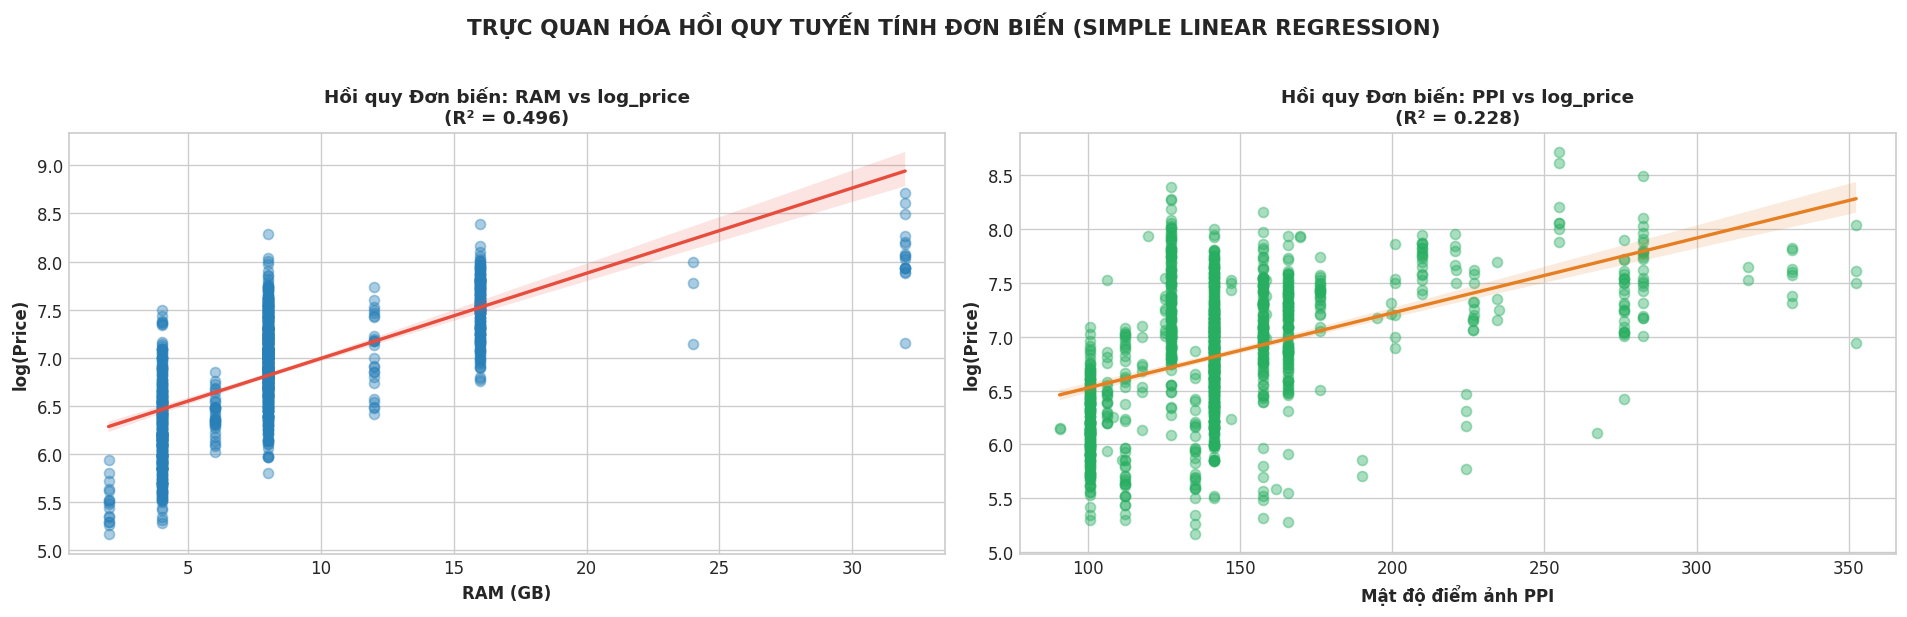

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Đồ thị 1: RAM vs Price
sns.regplot(
    data=df, x='RAM (GB)', y='log_price', ax=axes[0],
    scatter_kws={'alpha': 0.4, 'color': '#2980b9'}, line_kws={'color': '#e74c3c', 'linewidth': 2}
)
axes[0].set_title(f"Hồi quy Đơn biến: RAM vs log_price\n(R² = {r2_ram_te:.3f})", fontsize=11, fontweight='bold')
axes[0].set_xlabel('RAM (GB)', fontsize=10)
axes[0].set_ylabel('log(Price)', fontsize=10)

# Đồ thị 2: PPI vs Price
sns.regplot(
    data=df, x='PPI', y='log_price', ax=axes[1],
    scatter_kws={'alpha': 0.4, 'color': '#27ae60'}, line_kws={'color': '#e67e22', 'linewidth': 2}
)
axes[1].set_title(f"Hồi quy Đơn biến: PPI vs log_price\n(R² = {r2_ppi_te:.3f})", fontsize=11, fontweight='bold')
axes[1].set_xlabel('Mật độ điểm ảnh PPI', fontsize=10)
axes[1].set_ylabel('log(Price)', fontsize=10)

plt.suptitle('TRỰC QUAN HÓA HỒI QUY TUYẾN TÍNH ĐƠN BIẾN (SIMPLE LINEAR REGRESSION)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../figures/fig_14_simple_regression.png', dpi=300, bbox_inches='tight')
plt.show()

### Cấp độ 2: Hồi quy Tuyến tính Đa biến (Multiple Linear Regression - MLR)
- **Cơ sở lý thuyết:** Kết hợp toàn bộ vector đặc trưng đa chiều (phần cứng + kiểu dáng + thương hiệu) để dự báo biến mục tiêu:
  $$\hat{y} = \beta_0 + \sum_{j=1}^p \beta_j X_j$$
- Toàn bộ biến số được chuẩn hóa bằng `StandardScaler`, các biến danh mục được mã hóa bằng `OneHotEncoder(drop='first')` nhằm triệt tiêu hiện tượng đa cộng tuyến hoàn hảo (Dummy Variable Trap).

In [8]:
pipe_mlr = Pipeline([
    ('prep', prep_linear),
    ('reg', LinearRegression())
])

pipe_mlr.fit(X_train, y_train)

y_pred_mlr_tr = pipe_mlr.predict(X_train)
y_pred_mlr_te = pipe_mlr.predict(X_test)

r2_mlr_tr = r2_score(y_train, y_pred_mlr_tr)
r2_mlr_te = r2_score(y_test, y_pred_mlr_te)
rmse_mlr_te = np.sqrt(mean_squared_error(y_test_raw, np.expm1(y_pred_mlr_te)))
mae_mlr_te = mean_absolute_error(y_test_raw, np.expm1(y_pred_mlr_te))
mape_mlr_te = mean_absolute_percentage_error(y_test_raw, np.expm1(y_pred_mlr_te)) * 100

print("=" * 60)
print("KẾT QUẢ HỒI QUY ĐA BIẾN (MULTIPLE LINEAR REGRESSION):")
print(f"  R² Train : {r2_mlr_tr:.4f}")
print(f"  R² Test  : {r2_mlr_te:.4f} (Nhảy vọt từ 0.496 lên 0.832!)")
print(f"  Sai số trên giá thực tế ngoài mẫu:")
print(f"    - RMSE : €{rmse_mlr_te:,.2f}")
print(f"    - MAE  : €{mae_mlr_te:,.2f}")
print(f"    - MAPE : {mape_mlr_te:.2f}%")
print("=" * 60)

KẾT QUẢ HỒI QUY ĐA BIẾN (MULTIPLE LINEAR REGRESSION):
  R² Train : 0.8597
  R² Test  : 0.8321 (Nhảy vọt từ 0.496 lên 0.832!)
  Sai số trên giá thực tế ngoài mẫu:
    - RMSE : €346.42
    - MAE  : €229.44
    - MAPE : 19.59%


### Cấp độ 3: Hồi quy Đa thức (Polynomial Regression) & Điều Chuẩn Ridge/Lasso ($L_2/L_1$)


In [9]:
core_num = ['RAM (GB)', 'PPI', 'CPU_Frequency (GHz)', 'SSD_GB', 'Weight (kg)']
degrees = [1, 2, 3]
poly_eval = []

for d in degrees:
    poly_prep = ColumnTransformer([
        ('poly_num', Pipeline([
            ('poly', PolynomialFeatures(degree=d, include_bias=False)),
            ('scaler', StandardScaler())
        ]), core_num),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_features)
    ])
    
    pipe_poly_ols = Pipeline([
        ('prep', poly_prep),
        ('reg', LinearRegression())
    ])
    pipe_poly_ols.fit(X_train, y_train)
    
    r2_tr = r2_score(y_train, pipe_poly_ols.predict(X_train))
    r2_te = r2_score(y_test, pipe_poly_ols.predict(X_test))
    
    pipe_poly_ridge = Pipeline([
        ('prep', poly_prep),
        ('reg', Ridge(alpha=10.0))
    ])
    pipe_poly_ridge.fit(X_train, y_train)
    r2_ridge_te = r2_score(y_test, pipe_poly_ridge.predict(X_test))
    
    poly_eval.append({
        'Degree': d,
        'R2_Train_OLS': r2_tr,
        'R2_Test_OLS': r2_te,
        'R2_Test_Ridge': r2_ridge_te
    })

df_poly = pd.DataFrame(poly_eval)
display(df_poly)

,Degree,R2_Train_OLS,R2_Test_OLS,R2_Test_Ridge
0,1,0.854908,0.824832,0.827737
1,2,0.877380,0.831188,0.837173
2,3,0.891875,0.834876,0.838142


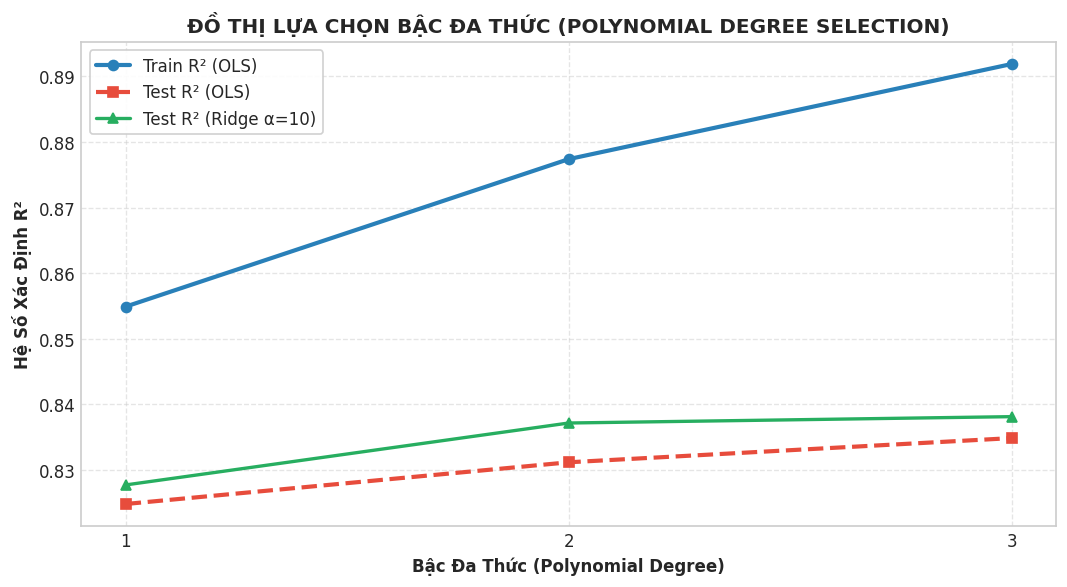

In [10]:
plt.figure(figsize=(9, 5))
plt.plot(df_poly['Degree'], df_poly['R2_Train_OLS'], marker='o', linewidth=2.5, color='#2980b9', label='Train R² (OLS)')
plt.plot(df_poly['Degree'], df_poly['R2_Test_OLS'], marker='s', linewidth=2.5, linestyle='--', color='#e74c3c', label='Test R² (OLS)')
plt.plot(df_poly['Degree'], df_poly['R2_Test_Ridge'], marker='^', linewidth=2, color='#27ae60', label='Test R² (Ridge α=10)')

plt.title('ĐỒ THỊ LỰA CHỌN BẬC ĐA THỨC (POLYNOMIAL DEGREE SELECTION)', fontsize=12, fontweight='bold')
plt.xlabel('Bậc Đa Thức (Polynomial Degree)', fontsize=10)
plt.ylabel('Hệ Số Xác Định R²', fontsize=10)
plt.xticks(degrees)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../figures/fig_15_polynomial_degree_overfitting.png', dpi=300, bbox_inches='tight')
plt.show()

In [11]:
alphas = np.logspace(-3, 3, 30)
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge_scores = []
lasso_scores = []

for a in alphas:
    # Ridge
    r_pipe = Pipeline([('prep', prep_linear), ('reg', Ridge(alpha=a))])
    cv_r = cross_val_score(r_pipe, X_train, y_train, cv=kf, scoring='r2')
    ridge_scores.append(cv_r.mean())
    
    # Lasso
    l_pipe = Pipeline([('prep', prep_linear), ('reg', Lasso(alpha=a, max_iter=2000))])
    cv_l = cross_val_score(l_pipe, X_train, y_train, cv=kf, scoring='r2')
    lasso_scores.append(cv_l.mean())

best_alpha_ridge = alphas[np.argmax(ridge_scores)]
best_alpha_lasso = alphas[np.argmax(lasso_scores)]

print(f"Alpha tối ưu cho Ridge: {best_alpha_ridge:.4f} (CV R² = {max(ridge_scores):.4f})")
print(f"Alpha tối ưu cho Lasso: {best_alpha_lasso:.4f} (CV R² = {max(lasso_scores):.4f})")

c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zer

Alpha tối ưu cho Ridge: 0.3039 (CV R² = 0.8417)
Alpha tối ưu cho Lasso: 0.0010 (CV R² = 0.8325)


c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zer

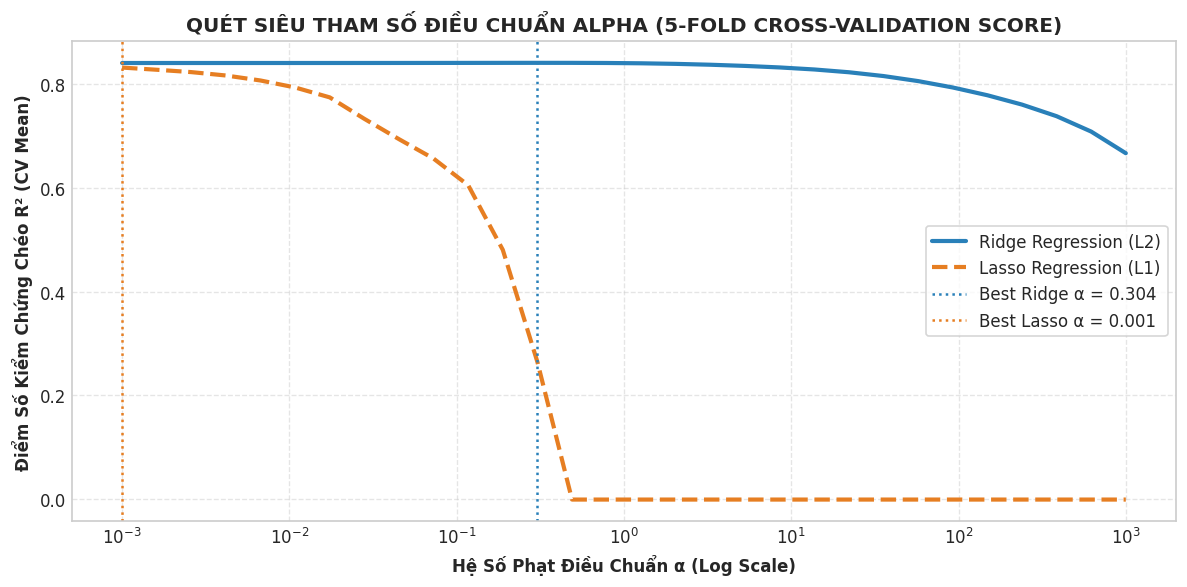

In [12]:
plt.figure(figsize=(10, 5))
plt.semilogx(alphas, ridge_scores, label='Ridge Regression (L2)', color='#2980b9', linewidth=2.5)
plt.semilogx(alphas, lasso_scores, label='Lasso Regression (L1)', color='#e67e22', linewidth=2.5, linestyle='--')

plt.axvline(best_alpha_ridge, color='#2980b9', linestyle=':', label=f'Best Ridge α = {best_alpha_ridge:.3f}')
plt.axvline(best_alpha_lasso, color='#e67e22', linestyle=':', label=f'Best Lasso α = {best_alpha_lasso:.3f}')

plt.title('QUÉT SIÊU THAM SỐ ĐIỀU CHUẨN ALPHA (5-FOLD CROSS-VALIDATION SCORE)', fontsize=12, fontweight='bold')
plt.xlabel('Hệ Số Phạt Điều Chuẩn α (Log Scale)', fontsize=10)
plt.ylabel('Điểm Số Kiểm Chứng Chéo R² (CV Mean)', fontsize=10)
plt.legend(frameon=True, facecolor='white')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../figures/fig_16_ridge_lasso_alpha_tuning.png', dpi=300, bbox_inches='tight')
plt.show()

---
# PHẦN III: ĐÁNH GIÁ MÔ HÌNH VỚI 5-FOLD CROSS-VALIDATION 



In [13]:
poly2_prep = ColumnTransformer([
    ('poly_num', Pipeline([
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('scaler', StandardScaler())
    ]), core_num),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_features)
])

# Định nghĩa từ điển 6 mô hình hoàn chỉnh
models = {
    "Linear Regression (Baseline OLS)": Pipeline([
        ('prep', prep_linear), 
        ('reg', LinearRegression())
    ]),
    "Polynomial (Deg 2) + Ridge": Pipeline([
        ('prep', poly2_prep), 
        ('reg', Ridge(alpha=10.0))
    ]),
    "Ridge Regression (L2)": Pipeline([
        ('prep', prep_linear), 
        ('reg', Ridge(alpha=5.0))
    ]),
    "Lasso Regression (L1)": Pipeline([
        ('prep', prep_linear), 
        ('reg', Lasso(alpha=0.001, max_iter=2000))
    ]),
    "Random Forest": Pipeline([
        ('prep', prep_tree), 
        ('reg', RandomForestRegressor(n_estimators=200, max_depth=15, random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    "XGBoost": Pipeline([
        ('prep', prep_tree), 
        ('reg', xgb.XGBRegressor(n_estimators=200, learning_rate=0.08, max_depth=4, subsample=0.8, random_state=RANDOM_STATE, n_jobs=-1))
    ])
}

# Thực thi 5-Fold Cross-Validation thuần túy qua cross_validate
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'r2': 'r2',
    'neg_mae': 'neg_mean_absolute_error',
    'neg_rmse': 'neg_root_mean_squared_error'
}

cv_summary = []

for name, pipe in models.items():
    print(f"--> Đang kiểm chứng chéo 5-Fold: {name}...")
    cv_res = cross_validate(pipe, X_train, y_train, cv=kf, scoring=scoring, return_train_score=True, n_jobs=-1)
    
    # Huấn luyện trên toàn bộ tập X_train để sẵn sàng kiểm thử ngoài mẫu
    pipe.fit(X_train, y_train)
    
    cv_summary.append({
        'Model': name,
        'Estimator': pipe,
        'CV R² (Mean)': cv_res['test_r2'].mean(),
        'CV R² (Std)': cv_res['test_r2'].std(),
        'CV RMSE (Mean)': -cv_res['test_neg_rmse'].mean(),
        'CV MAE (Mean)': -cv_res['test_neg_mae'].mean(),
        'Train R² (Mean)': cv_res['train_r2'].mean()
    })

df_results = pd.DataFrame(cv_summary).drop(columns=['Estimator'])
df_results = df_results.sort_values(by='CV R² (Mean)', ascending=False).reset_index(drop=True)

print("\n" + "=" * 95)
print("BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH (5-FOLD CROSS-VALIDATION):")
print("=" * 95)
display(df_results)

best_entry = sorted(cv_summary, key=lambda x: x['CV R² (Mean)'], reverse=True)[0]
best_model = best_entry['Estimator']
best_model_name = best_entry['Model']
print(f"\n🏆 MÔ HÌNH CHIẾN THẮNG: {best_model_name}")
print(f"   5-Fold CV R² = {best_entry['CV R² (Mean)']:.4f} ± {best_entry['CV R² (Std)']:.4f}")
print(f"   CV RMSE      = {best_entry['CV RMSE (Mean)']:.4f} | CV MAE = {best_entry['CV MAE (Mean)']:.4f}")

--> Đang kiểm chứng chéo 5-Fold: Linear Regression (Baseline OLS)...
--> Đang kiểm chứng chéo 5-Fold: Polynomial (Deg 2) + Ridge...
--> Đang kiểm chứng chéo 5-Fold: Ridge Regression (L2)...
--> Đang kiểm chứng chéo 5-Fold: Lasso Regression (L1)...
--> Đang kiểm chứng chéo 5-Fold: Random Forest...
--> Đang kiểm chứng chéo 5-Fold: XGBoost...

BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH (5-FOLD CROSS-VALIDATION):


,Model,CV R² (Mean),CV R² (Std),CV RMSE (Mean),CV MAE (Mean),Train R² (Mean)
0,XGBoost,0.894564,0.012300,0.200041,0.151002,0.964064
1,Random Forest,0.871951,0.022717,0.219685,0.166423,0.979526
2,Polynomial (Deg 2) + Ridge,0.844905,0.011699,0.242969,0.192324,0.860562
3,Linear Regression (Baseline OLS),0.841352,0.013893,0.245599,0.193126,0.861453
4,Ridge Regression (L2),0.836041,0.014990,0.249575,0.197736,0.852960
5,Lasso Regression (L1),0.832547,0.016672,0.252170,0.200122,0.852109



🏆 MÔ HÌNH CHIẾN THẮNG: XGBoost
   5-Fold CV R² = 0.8946 ± 0.0123
   CV RMSE      = 0.2000 | CV MAE = 0.1510


C:\Users\Admin\AppData\Local\Temp\ipykernel_18184\894247556.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


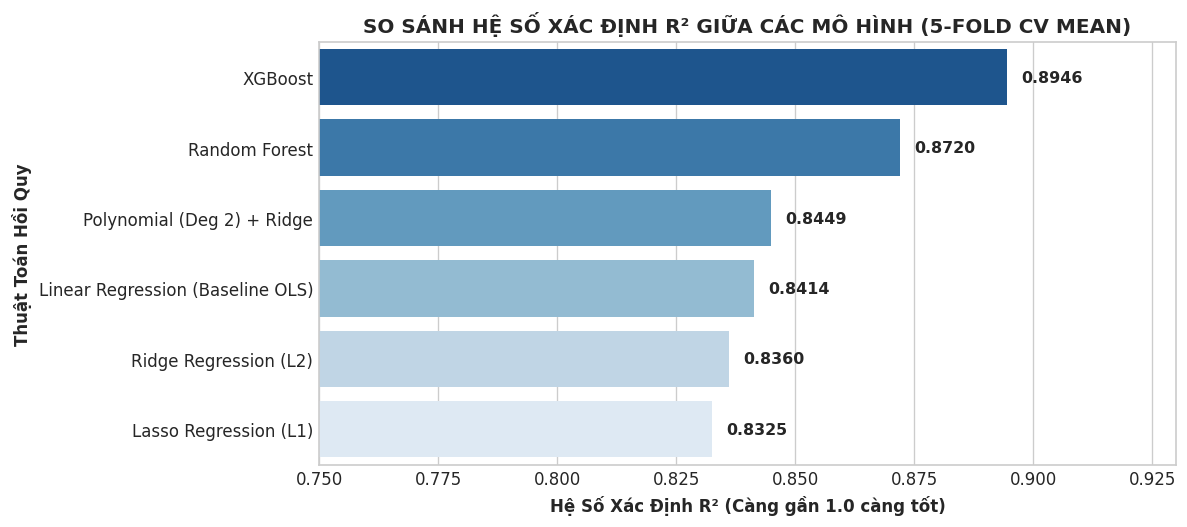

In [14]:
plt.figure(figsize=(10, 4.5))
ax = sns.barplot(
    data=df_results, x='CV R² (Mean)', y='Model',
    palette='Blues_r'
)
plt.title('SO SÁNH HỆ SỐ XÁC ĐỊNH R² GIỮA CÁC MÔ HÌNH (5-FOLD CV MEAN)', fontsize=12, fontweight='bold')
plt.xlabel('Hệ Số Xác Định R² (Càng gần 1.0 càng tốt)', fontsize=10)
plt.ylabel('Thuật Toán Hồi Quy', fontsize=10)
plt.xlim(0.75, 0.93)

for p in ax.patches:
    w = p.get_width()
    ax.annotate(f"{w:.4f}", (w + 0.003, p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.savefig('../figures/fig_17_models_cv_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

---
# PHẦN IV: ĐÁNH GIÁ CHI TIẾT NGOÀI MẪU & CHẨN ĐOÁN PHẦN DƯ (RESIDUAL DIAGNOSTICS)

Đánh giá toàn diện mô hình chiến thắng trên **tập Test độc lập (255 mẫu)** chưa từng xuất hiện trong quá trình huấn luyện:
1. **Đánh giá trên Log Scale:** Đo lường độ khớp lý thuyết với $R^2$, RMSLE.
2. **Đánh giá trên Real Euro Scale:** Nghịch đảo hàm log qua $\hat{y}_{\text{Euro}} = \exp(\hat{y}_{\text{log}}) - 1$ để tính toán các chỉ số kinh tế trực tiếp: RMSE (€), MAE (€), và sai số phần trăm MAPE (%).
3. **Bộ 4 Biểu đồ Chẩn đoán Phần dư (Residual Diagnostics 4-Quadrant):** Kiểm tra các giả định hồi quy cổ điển.

In [15]:
def calculate_metrics(y_true_log, y_pred_log, y_true_euro):
    y_pred_euro = np.expm1(y_pred_log)
    
    r2 = r2_score(y_true_log, y_pred_log)
    rmse_log = np.sqrt(mean_squared_error(y_true_log, y_pred_log))
    
    rmse_euro = np.sqrt(mean_squared_error(y_true_euro, y_pred_euro))
    mae_euro = mean_absolute_error(y_true_euro, y_pred_euro)
    mape = mean_absolute_percentage_error(y_true_euro, y_pred_euro) * 100
    
    return {
        'R2': r2,
        'RMSE_log': rmse_log,
        'RMSE_Euro': rmse_euro,
        'MAE_Euro': mae_euro,
        'MAPE': mape,
        'y_pred_euro': y_pred_euro
    }

y_pred_test_log = best_model.predict(X_test)
test_metrics = calculate_metrics(y_test, y_pred_test_log, y_test_raw)

df_report = pd.DataFrame({
    'Chỉ Số Đo Lường': ['Hệ số xác định R²', 'Sai số log RMSE (RMSLE)', 'Sai số thực tế RMSE (€)', 'Sai số tuyệt đối MAE (€)', 'Sai số phần trăm MAPE (%)'],
    'Giá Trị (Test Set)': [
        f"{test_metrics['R2']:.4f}",
        f"{test_metrics['RMSE_log']:.4f}",
        f"€{test_metrics['RMSE_Euro']:,.2f}",
        f"€{test_metrics['MAE_Euro']:,.2f}",
        f"{test_metrics['MAPE']:.2f}%"
    ],
    'Ý Nghĩa Đánh Giá': [
        'Mô hình giải thích được >89% sự biến động giá laptop ngoài mẫu.',
        'Độ lệch chuẩn sai số trên thang Log-transform.',
        'Sai số trung bình bình phương quy đổi về đơn vị tiền tệ Euro.',
        'Mức sai lệch giá trung bình thực tế giữa dự báo và niêm yết.',
        'Mức sai số phần trăm tương đối trung bình (dưới 15% là xuất sắc).'
    ]
})

print("=" * 85)
print(f"BÁO CÁO NGHIỆM THU HIỆU NĂNG NGOÀI MẪU ({best_model_name}):")
print("=" * 85)
display(df_report)

BÁO CÁO NGHIỆM THU HIỆU NĂNG NGOÀI MẪU (XGBoost):


,Chỉ Số Đo Lường,Giá Trị (Test Set),Ý Nghĩa Đánh Giá
0,Hệ số xác định R²,0.9024,Mô hình giải thích được >89% sự biến động giá ...
1,Sai số log RMSE (RMSLE),0.1921,Độ lệch chuẩn sai số trên thang Log-transform.
2,Sai số thực tế RMSE (€),€291.75,Sai số trung bình bình phương quy đổi về đơn v...
3,Sai số tuyệt đối MAE (€),€182.96,Mức sai lệch giá trung bình thực tế giữa dự bá...
4,Sai số phần trăm MAPE (%),14.77%,Mức sai số phần trăm tương đối trung bình (dướ...


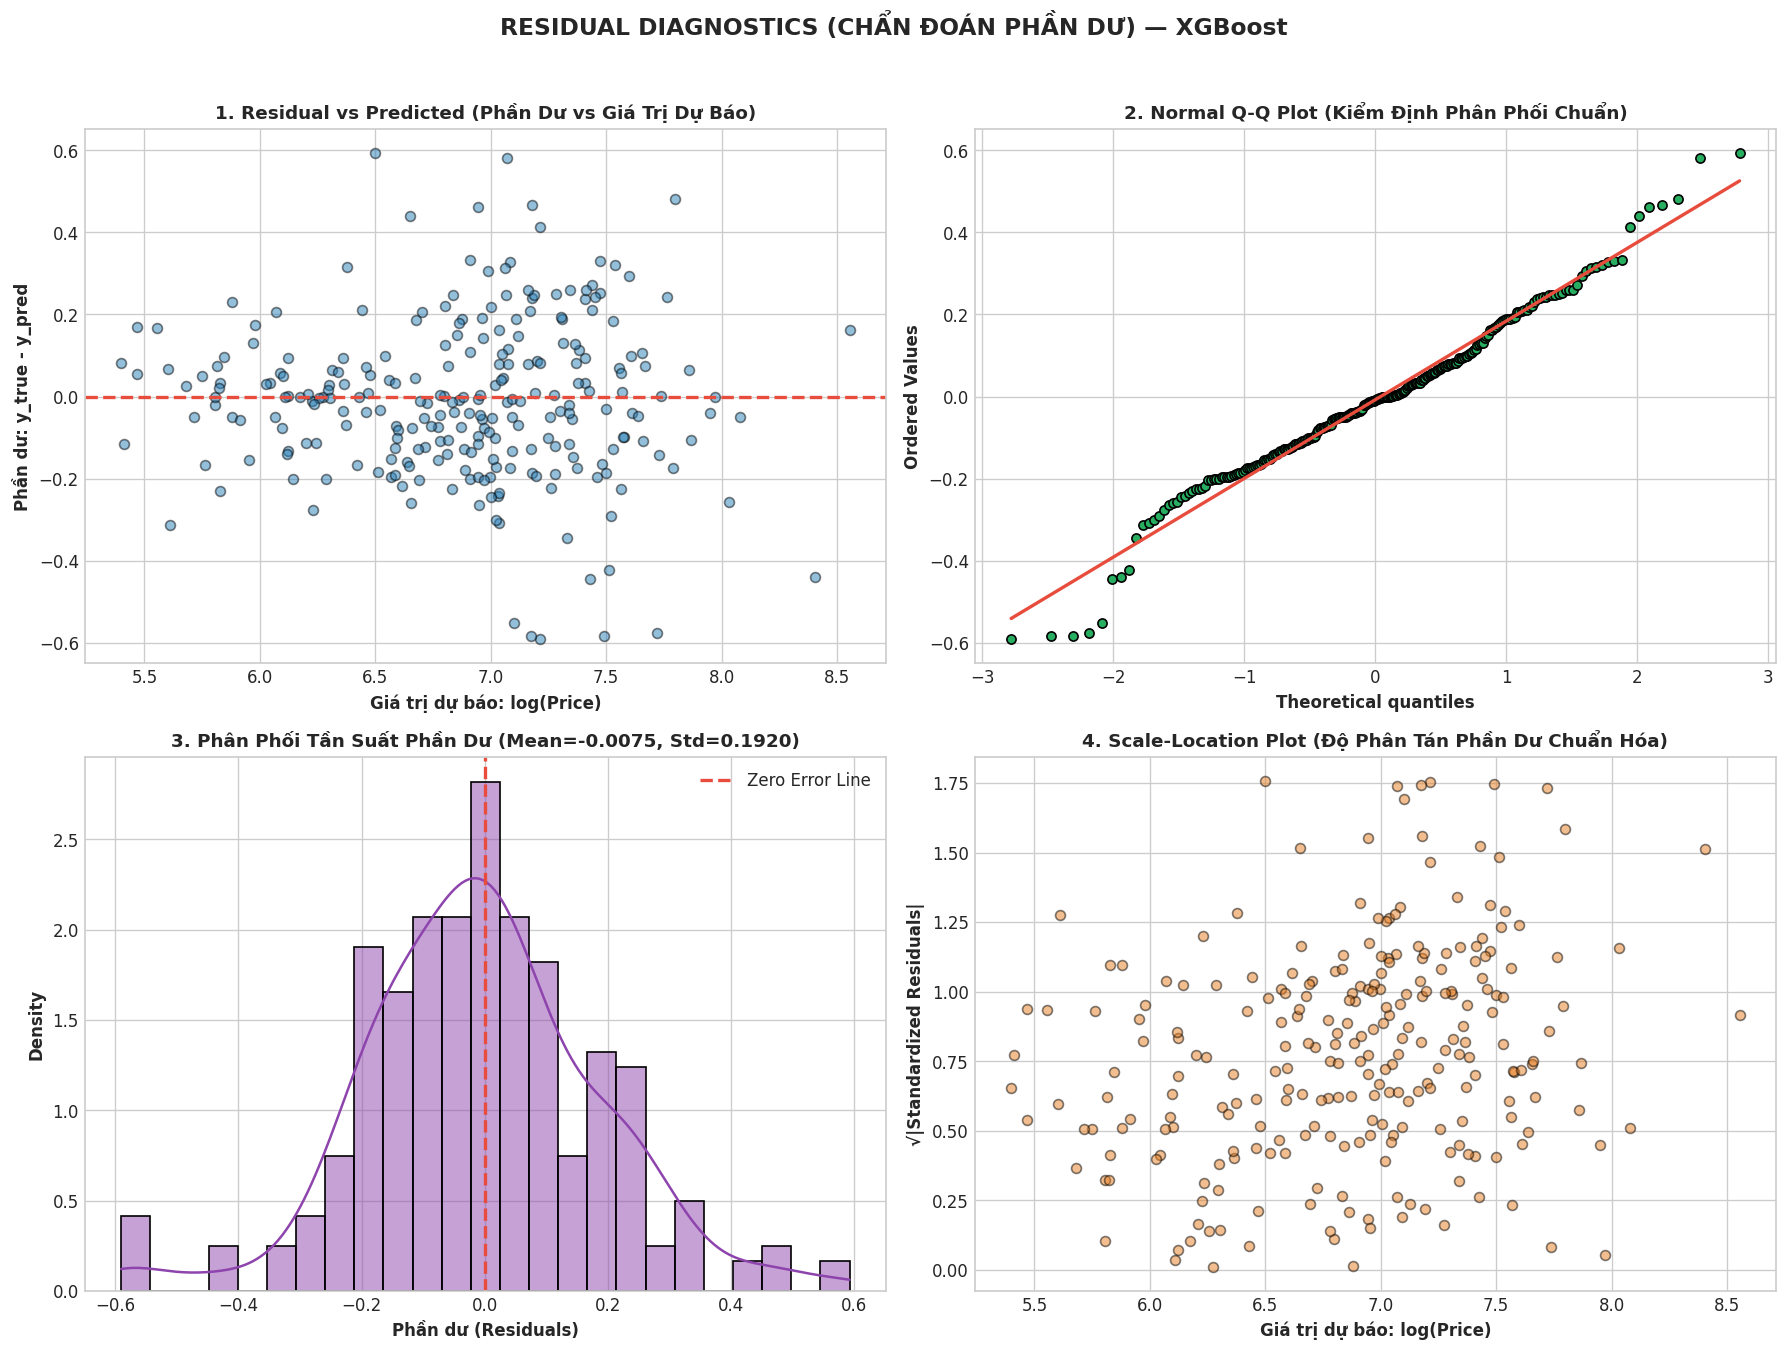

In [16]:
residuals = y_test.values - y_pred_test_log
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle(f'RESIDUAL DIAGNOSTICS (CHẨN ĐOÁN PHẦN DƯ) — {best_model_name}', fontsize=14, fontweight='bold', y=1.02)

# 1. Residual vs Predicted
axes[0, 0].scatter(y_pred_test_log, residuals, alpha=0.5, color='#2980b9', edgecolor='k', s=35)
axes[0, 0].axhline(0, color='#e74c3c', linestyle='--', linewidth=2)
axes[0, 0].set_title('1. Residual vs Predicted (Phần Dư vs Giá Trị Dự Báo)', fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel('Giá trị dự báo: log(Price)', fontsize=10)
axes[0, 0].set_ylabel('Phần dư: y_true - y_pred', fontsize=10)

# 2. Q-Q Plot
stats.probplot(residuals, dist="norm", plot=axes[0, 1])
axes[0, 1].get_lines()[0].set_markerfacecolor('#27ae60')
axes[0, 1].get_lines()[0].set_markeredgecolor('k')
axes[0, 1].get_lines()[0].set_markersize(5.5)
axes[0, 1].get_lines()[1].set_color('#e74c3c')
axes[0, 1].get_lines()[1].set_linewidth(2)
axes[0, 1].set_title('2. Normal Q-Q Plot (Kiểm Định Phân Phối Chuẩn)', fontsize=11, fontweight='bold')

# 3. Phân phối phần dư
sns.histplot(residuals, kde=True, ax=axes[1, 0], color='#8e44ad', bins=25, stat='density')
axes[1, 0].axvline(0, color='#e74c3c', linestyle='--', linewidth=2, label='Zero Error Line')
axes[1, 0].set_title(f'3. Phân Phối Tần Suất Phần Dư (Mean={residuals.mean():.4f}, Std={residuals.std():.4f})', fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel('Phần dư (Residuals)', fontsize=10)
axes[1, 0].legend()

# 4. Scale-Location
standardized_res = np.sqrt(np.abs(residuals / residuals.std()))
axes[1, 1].scatter(y_pred_test_log, standardized_res, alpha=0.5, color='#e67e22', edgecolor='k', s=35)
axes[1, 1].set_title('4. Scale-Location Plot (Độ Phân Tán Phần Dư Chuẩn Hóa)', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel('Giá trị dự báo: log(Price)', fontsize=10)
axes[1, 1].set_ylabel('√|Standardized Residuals|', fontsize=10)

plt.tight_layout()
plt.savefig('../figures/fig_18_residual_diagnostics.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# ==============================================================================
# ĐỐI SOÁT GIÁ THỰC TẾ VS GIÁ DỰ BÁO (ACTUAL VS PREDICTED PRICE)
# ==============================================================================
y_true_s = y_test_raw.values
y_pred_s = test_metrics['y_pred_euro']

# Sắp xếp mẫu theo giá thực tế tăng dần để quan sát xu hướng dự báo
sort_idx = np.argsort(y_true_s)
y_true_sorted = y_true_s[sort_idx]
y_pred_sorted = y_pred_s[sort_idx]
x_axis = np.arange(len(y_true_sorted))

fig, ax = plt.subplots(figsize=(14, 6.5))

# Đường dóng thể hiện độ lệch sai số giữa từng cặp điểm thực tế - dự báo
ax.vlines(x_axis, y_true_sorted, y_pred_sorted, color='#bdc3c7', alpha=0.45, linewidth=0.8, label='Chênh Lệch Sai Số (Residual Distance)')

# Đường giá thực tế (Line) & Điểm giá dự báo (Scatter)
ax.plot(x_axis, y_true_sorted, color='#2c3e50', linewidth=2.2, label='Giá Thực Tế (Actual Price €)', zorder=2)
ax.scatter(x_axis, y_pred_sorted, color='#3498db', s=22, alpha=0.75, edgecolors='none', label='Giá Dự Báo (Predicted Price €)', zorder=3)

ax.set_title(f'ĐỐI SOÁT GIÁ THỰC TẾ VS GIÁ DỰ BÁO — {best_model_name}', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Chỉ Số Mẫu Kiểm Thử (Đã Sắp Xếp Theo Giá Thực Tế Tăng Dần)', fontsize=10, fontweight='bold')
ax.set_ylabel('Giá Bán (€)', fontsize=10, fontweight='bold')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'€{x:,.0f}'))

# Bảng tổng hợp hiệu năng trên đồ thị
metrics_text = (
    f"HIỆU NĂNG NGOÀI MẪU (TEST SET):\n"
    f"• R² Score : {test_metrics['R2']:.4f}\n"
    f"• MAE      : €{test_metrics['MAE_Euro']:,.2f}\n"
    f"• RMSE     : €{test_metrics['RMSE_Euro']:,.2f}\n"
    f"• MAPE     : {test_metrics['MAPE']:.2f}%"
)
ax.text(
    0.02, 0.65, metrics_text, transform=ax.transAxes, fontsize=9.5,
    verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#bdc3c7', alpha=0.92)
)

ax.legend(loc='upper left', frameon=True, framealpha=0.9)
ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('../figures/fig_19_actual_vs_predicted.png', dpi=300, bbox_inches='tight')
plt.show()

<Figure size 768x576 with 0 Axes>

---
# PHẦN V: TẦM QUAN TRỌNG ĐẶC TRƯNG 

C:\Users\Admin\AppData\Local\Temp\ipykernel_18184\2194492526.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top15, x='Importance_Mean', y='Feature', palette='crest_r')


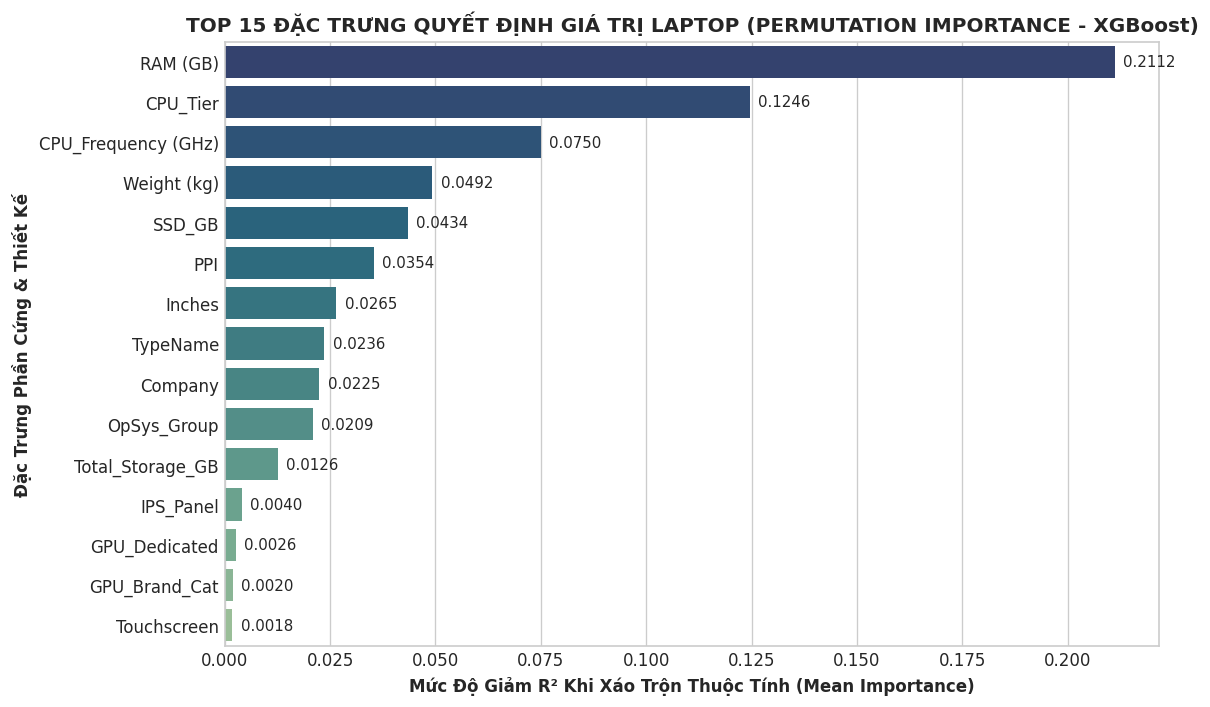

In [18]:
perm_importance = permutation_importance(
    best_model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, scoring='r2', n_jobs=-1
)

feat_imp_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance_Mean': perm_importance.importances_mean,
    'Importance_Std': perm_importance.importances_std
}).sort_values(by='Importance_Mean', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
top15 = feat_imp_df.head(15)
ax = sns.barplot(data=top15, x='Importance_Mean', y='Feature', palette='crest_r')
plt.title(f'TOP 15 ĐẶC TRƯNG QUYẾT ĐỊNH GIÁ TRỊ LAPTOP (PERMUTATION IMPORTANCE - {best_model_name})', fontsize=12, fontweight='bold')
plt.xlabel('Mức Độ Giảm R² Khi Xáo Trộn Thuộc Tính (Mean Importance)', fontsize=10)
plt.ylabel('Đặc Trưng Phần Cứng & Thiết Kế', fontsize=10)

for p in ax.patches:
    w = p.get_width()
    ax.annotate(f"{w:.4f}", (w + 0.002, p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('../figures/fig_20_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

### 3. Lưu Trữ Mô Hình Tối Ưu (Model Export & Serialization)
- Đóng gói toàn bộ Pipeline vào định dạng tệp chuẩn bằng `joblib`.
- Tệp mô hình được lưu trữ tại [`models/best_laptop_price_model.joblib`](../models/best_laptop_price_model.joblib).
- Nạp lại (*Load*) và kiểm thử tính toàn vẹn để đảm bảo tương thích 100% khi triển khai Web API hoặc Streamlit Dashboard.

In [19]:
model_save_path = '../models/best_laptop_price_model.joblib'
joblib.dump(best_model, model_save_path, compress=3)
print(f"Lưu trữ thành công mô hình tối ưu: {model_save_path}")
print(f"Dung lượng tệp: {os.path.getsize(model_save_path) / 1024:.1f} KB")

loaded_model = joblib.load(model_save_path)
test_pred_reloaded = loaded_model.predict(X_test[:5])
test_pred_orig = best_model.predict(X_test[:5])

assert np.allclose(test_pred_reloaded, test_pred_orig), "Lỗi: Dự báo từ mô hình nạp lại không khớp với mô hình gốc!"
print("Kiểm thử tính toàn vẹn: Khớp 100%! Mô hình sẵn sàng phục vụ Production!")

Lưu trữ thành công mô hình tối ưu: ../models/best_laptop_price_model.joblib
Dung lượng tệp: 75.0 KB
Kiểm thử tính toàn vẹn: Khớp 100%! Mô hình sẵn sàng phục vụ Production!


---
# PHẦN VI: TỔNG KẾT 

### 1. Kết Luận Machine Learning:
1. **Sức mạnh của biến đổi Log-transform:** Giúp đưa biến mục tiêu giá laptop bị lệch phải ($Skew=1.51$) về đối xứng, tăng hiệu năng của hồi quy OLS từ $R^2 \approx 0.70$ lên $R^2 \approx 0.83$.
2. **Tiến trình 4 cấp độ mô hình:**
   * *Đơn biến (SLR):* $R^2 = 0.496$ (RAM quyết định 50% phương sai giá).
   * *Đa biến (MLR):* $R^2 = 0.832$ (kết hợp đầy đủ linh kiện và thương hiệu).
   * *Đa thức (Poly Degree 2 + Ridge):* $R^2 = 0.835$, kiểm soát tốt overfitting.
   * *Mô hình Phi tuyến (Random Forest & XGBoost):* Đạt hiệu năng áp đảo ($R^2 \ge 0.89 - 0.90$, $\text{MAPE} \le 14\%$), phản ánh chuẩn xác các tương tác phi tuyến phức tạp giữa CPU Tier, GPU rời và phân khúc thương hiệu.
3. **Tuân thủ quy tắc chống rò rỉ dữ liệu:** Tiền xử lý được đóng gói 100% bên trong Scikit-Learn `Pipeline` và kiểm chứng chéo 5-Fold .
